In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from trRSA_cf import *
import json, os, sys, time, re

In [112]:
def load_curve_data(input_path: Path) -> np.ndarray:
    """
    Loads one subject's .npy or a folder of subjects' .npy files.
    Always returns a stacked array of shape (n_subs, n_models, tps).
    """
    if input_path.is_dir():
        files = sorted(input_path.glob("*.npy"))
        if not files:
            raise FileNotFoundError(f"No .npy files found in: {input_path}")
        data = [np.load(f, allow_pickle=True) for f in files]
        file_name_stem = None
    elif input_path.is_file():
        data = [np.load(input_path, allow_pickle=True)]
        file_name_stem = input_path.stem
    else:
        raise FileNotFoundError(f"Path does not exist: {input_path}")

    return np.stack(data), file_name_stem  # (n_subs, n_models, tps)

In [113]:
def load_model_labels(labels_path: Path, n_models: int) -> list:
    try:
        with open(labels_path, "r") as f:
            return json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        print(f"Warning: could not read model labels from {labels_path}, "
              f"falling back to generic names.")
        return [f"Model {i + 1}" for i in range(n_models)]

In [114]:
def run_cluster_stats(selected_model_lags, cluster_p_value_threshold, n_permutations=1000):
    """
    selected_model_lags: (n_subs, n_lags) for one model. Requires n_subs > 1.
    Returns a list of (start_idx, end_idx) for significant clusters.
    """
    from mne.stats import permutation_cluster_1samp_test  # imported lazily: only needed here

    T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(
        selected_model_lags,
        n_permutations=n_permutations,
        threshold=None,
        tail=1,
        n_jobs=1,
    )
    sig = np.where(cluster_p_values < cluster_p_value_threshold)[0]
    return [(clusters[i][0][0], clusters[i][0][-1]) for i in sig]

In [115]:
from matplotlib.ticker import FormatStrFormatter

def grid_plot(curve_data, show_sem=True, statistical_testing=True, cluster_p_value_threshold=0.05, fix_scales_range=None, output_dir=None, file_name=None):

    # prerequisits 
    n_subs, n_models, subsample_tps = curve_data.shape
    selected_models_labels = load_model_labels(labels_path, n_models)

    half = subsample_tps // 2
    lags = np.arange(subsample_tps) - half
    lags_in_seconds = lags / resolution
    n_models = len(selected_models_labels)

    if show_sem and n_subs > 1:
        std = np.std(curve_data, ddof=1, axis=0)
        sem = std / np.sqrt(n_subs)

    curve_averaged = np.mean(curve_data, axis=0)

    # plot
    fig, axs = plt.subplots(n_models, 1, figsize=(7, 3 * n_models), squeeze=False)

    for i in range(n_models):
        model_name = selected_models_labels[i]
        curve = np.asarray(curve_averaged[i])

        ax_lag = axs[i, 0]
        ax_lag.plot(lags_in_seconds, curve)

        ax_lag.axvline(0, color='gray', linestyle='--')
        ax_lag.axhline(0, color='gray', linestyle='--')
        ax_lag.set_xlabel('Time [s]', fontsize=7)
        ax_lag.set_ylabel('Correlation', fontsize=7)
        ax_lag.set_title(str(model_name), fontsize=8)

        # Peak of this model's curve
        peak_idx = int(np.argmax(curve))
        peak_lag = lags_in_seconds[peak_idx]
        peak_val = curve[peak_idx]

        ax_lag.plot(peak_lag, peak_val, 'ro', markersize=3)
        ax_lag.annotate(
            f'Lag: {peak_lag:.2f}s',
            xy=(peak_lag, peak_val),
            xytext=(peak_lag + 0.2, peak_val),
            arrowprops=dict(arrowstyle='->', color='red'),
            fontsize=7,
        )

        # fix scale
        if fix_scales_range:
            ax_lag.set_ylim(fix_scales_range)

        # standard error
        if show_sem:
            ax_lag.fill_between(lags_in_seconds, curve_averaged[i] - sem[i], curve_averaged[i] + sem[i], alpha=0.3)

        # statistical testing
        if statistical_testing and n_subs > 1:
            if curve_data.shape[0] > 1:
                clusters = run_cluster_stats(curve_data[:, i, :], cluster_p_value_threshold)
                print(f'significant clusters: {clusters}')
                for start, end in clusters:
                    ax_lag.axvspan(lags_in_seconds[start], lags_in_seconds[end], color='green', alpha=0.2)
            else:
                print(f"Skipping cluster stats for '{model_name}': need more than 1 subject.")

        # tick format
        ax_lag.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))

        # save path
        out_dir = get_unique_path(output_dir, file_name + '.png') if output_dir is not None else get_unique_path('_results', 'plot-output.png')
        print(output_dir)


    fig.tight_layout()
    fig.savefig(out_dir, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    
    return

## main

In [116]:
# you need to input:

path = Path('/Users/delacroix/Documents/Coding/dRSA/trRSA/_results/q75_indices-gpt')

resolution = 100
curve_data_path = path
labels_path = path / 'selected_model_labels.json'

output_dir = path.parent
output_dir.mkdir(parents=True, exist_ok=True)


# save file name
file_name = path.stem

In [117]:
curve_data, file_name_stem = load_curve_data(curve_data_path) # shape (n_subs, models, tps)

In [118]:
curve_data.shape # 4 files, 3 models 150 tps

(9, 5, 150)

Using a threshold of 1.859548
stat_fun(H1): min=0.09228801313459303 max=6.226273052109105
Running initial clustering …
Found 7 clusters


  0%|          | Permuting (exact test) : 0/511 [00:00<?,       ?it/s]

significant clusters: [(np.int64(33), np.int64(149))]
/Users/delacroix/Documents/Coding/dRSA/trRSA/_results
Using a threshold of 1.859548
stat_fun(H1): min=1.8992227853332275 max=4.922422702944893
Running initial clustering …
Found 1 cluster


  0%|          | Permuting (exact test) : 0/511 [00:00<?,       ?it/s]

significant clusters: [(np.int64(0), np.int64(149))]
/Users/delacroix/Documents/Coding/dRSA/trRSA/_results
Using a threshold of 1.859548
stat_fun(H1): min=1.4415284736883753 max=4.299060774422699
Running initial clustering …
Found 3 clusters


  0%|          | Permuting (exact test) : 0/511 [00:00<?,       ?it/s]

significant clusters: [(np.int64(26), np.int64(149))]
/Users/delacroix/Documents/Coding/dRSA/trRSA/_results
Using a threshold of 1.859548
stat_fun(H1): min=0.994681254959503 max=3.4685292979386495
Running initial clustering …
Found 14 clusters


  0%|          | Permuting (exact test) : 0/511 [00:00<?,       ?it/s]

significant clusters: [(np.int64(61), np.int64(98))]
/Users/delacroix/Documents/Coding/dRSA/trRSA/_results
Using a threshold of 1.859548
stat_fun(H1): min=0.5572486780023574 max=3.757209242679591
Running initial clustering …
Found 12 clusters


  0%|          | Permuting (exact test) : 0/511 [00:00<?,       ?it/s]

significant clusters: []
/Users/delacroix/Documents/Coding/dRSA/trRSA/_results


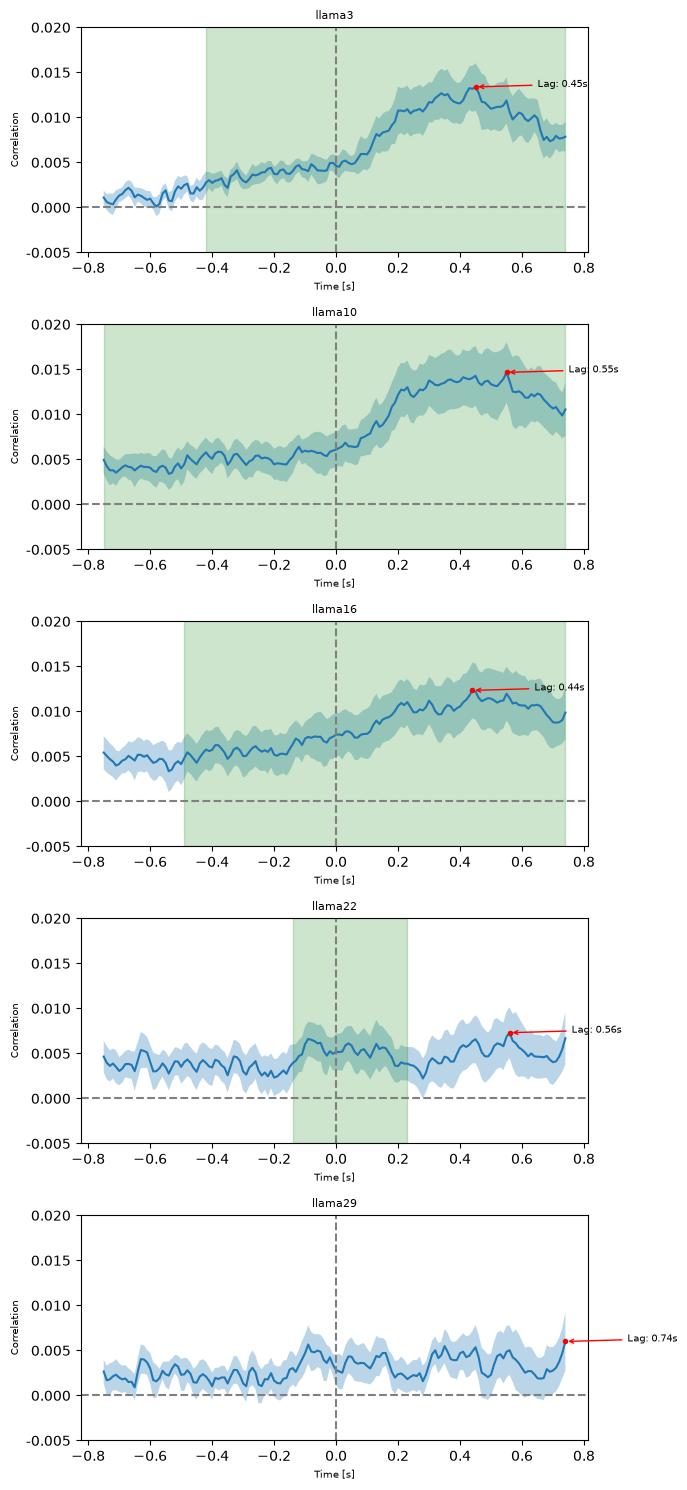

In [119]:
grid_plot(curve_data, statistical_testing=True, cluster_p_value_threshold=0.05, fix_scales_range=[-0.005, 0.02], output_dir=output_dir, file_name=file_name)

## merge plot

In [ ]:
_HEX_COLORS = ["#19669d", "#a08b23", "#1e631e", "#831313", "#42167e", "#8d4d16",
               "#2f3c3e", "#5e3c99", "#b15928", "#3182bd", "#31a354", "#e6550d",
               "#756bb1", "#636363"]

def plot_merged(lags_in_seconds, models_curves_list, model_labels, sem=None, output_dir=None):
    n_models = len(model_labels)
    colors = [_HEX_COLORS[i % len(_HEX_COLORS)] for i in range(n_models)]

    plt.figure(figsize=(8, 3))
    for i, label in enumerate(model_labels):
        plt.plot(lags_in_seconds, models_curves_list[i], label=label, color=colors[i])
        if sem is not None:
            plt.fill_between(lags_in_seconds, models_curves_list[i] - sem[i], models_curves_list[i] + sem[i],
                              alpha=0.3, color=colors[i])

    plt.axvline(0, color='gray', linestyle='--')
    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('Time [s]')
    plt.ylabel('Correlation')
    plt.legend()
    plt.tight_layout()

    output_dir = output_dir or '_results'
    out_path = get_unique_path(output_dir, 'merge-into-one.png')
    plt.savefig(out_path, dpi=300)
    plt.close()
    return out_path